# Sampling one interference pattern twice
### Detectability of GNSS multipath classes from spatial and inter-frequency C/N0 differences under receiver quantization and noise

This notebook runs the experiments E1–E5 from the `cn0sampling` package in this repository and reproduces every
figure and table in `results/`.

**Scope.** Idealized narrowband interference (image-source plane waves, Fresnel reflection, scalar antenna channel model)
and a receiver reporting model (Gaussian estimation noise, then uniform quantization). No measured observations,
pseudorange solution or validated antenna pattern are involved; the outputs are model-based sensitivity evidence.

**Reproducibility.** Seeds are fixed; the archived `results/results.json` was produced with the versions listed in
`requirements.txt`. Running this notebook regenerates it in a local output directory. Nothing is written outside that
directory and no packages are installed without the explicit opt-in cell below.

Repository: https://github.com/hamamh66/cn0-interference-sampling  ·  License: MIT

## 0. Environment
On Google Colab the repository is cloned into the local disk (`/content`), never into Drive. Locally, run from the repository root after `pip install -e .`.

In [1]:
import importlib, os, subprocess, sys
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    os.chdir("/content")
    if not Path("cn0-interference-sampling").exists():
        subprocess.check_call(["git", "clone", "--depth", "1", "https://github.com/hamamh66/cn0-interference-sampling.git"])
    os.chdir("cn0-interference-sampling")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-e", "."])   # opt-in install, Colab only
elif not Path("cn0sampling").exists():
    os.chdir(Path.cwd().parent)          # notebooks/ -> repository root
import platform, numpy, scipy, sklearn, matplotlib
print("Python", platform.python_version(), "| numpy", numpy.__version__, "| scipy", scipy.__version__,
      "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)
print("Repository root:", Path.cwd())

Python 3.11.15 | numpy 2.4.4 | scipy 1.17.1 | scikit-learn 1.8.0 | matplotlib 3.10.9
Repository root: /home/claude/repo


In [2]:
# Experiment size. Archived-results settings: N = 12000 scenes per split, SEEDS = (0, 1, 2, 3, 4)  (~15 s on a laptop CPU).
N = 12000
SEEDS = (0, 1, 2, 3, 4)
OUTPUT_DIR = Path("cn0_outputs")          # local; on Colab this is /content/cn0-interference-sampling/cn0_outputs

from cn0sampling import simulation as sim
from cn0sampling import run_experiments as experiments
from cn0sampling import make_diagrams as diagrams

## 1. Physical and numerical self-checks
Ground path excess, phase-step convention, exact horizontal-baseline null, zero-baseline identity, weak-signal RMS formula, PMF normalization and null Bayes error, identical-input quantization, correlated-noise variance.

In [3]:
sim.self_checks()

Passed: geometry, phase convention, blind cases, paired identity, RMS approximation, PMF normalization, binary null.


## 2. Run E1–E5
All feature configurations share the same train/test scenes and reference-channel observations within each seed; train and test scenes are independent and exactly class-balanced.

In [4]:
results = experiments.run_all(n=N, seeds=SEEDS, output_dir=OUTPUT_DIR)
diagrams.main(OUTPUT_DIR / "figures")
print(f"Run completed in {results['runtime_s']:.1f} s. Outputs in {OUTPUT_DIR.resolve()}")
print("Tables:", sorted(p.name for p in (OUTPUT_DIR / 'tables').glob('*.tex')))

Passed: geometry, phase convention, blind cases, paired identity, RMS approximation, PMF normalization, binary null.


Completed paired seed 0


Completed paired seed 1


Completed paired seed 2


Completed paired seed 3


Completed paired seed 4


Run completed in 11.8 s. Outputs in /home/claude/repo/cn0_outputs
Tables: ['table_e2.tex', 'table_e3.tex', 'table_e5.tex', 'table_recall.tex']


## 3. E1–E2: geometry and baseline response
Zero spatial differences for ideal LOS, ground-only horizontal samples and single-ray NLOS are model identities. Finite edges, changing amplitudes and real antenna mismatch can break them. A quantization step drawn on a plot is a scale reference, not a hard detectability threshold.

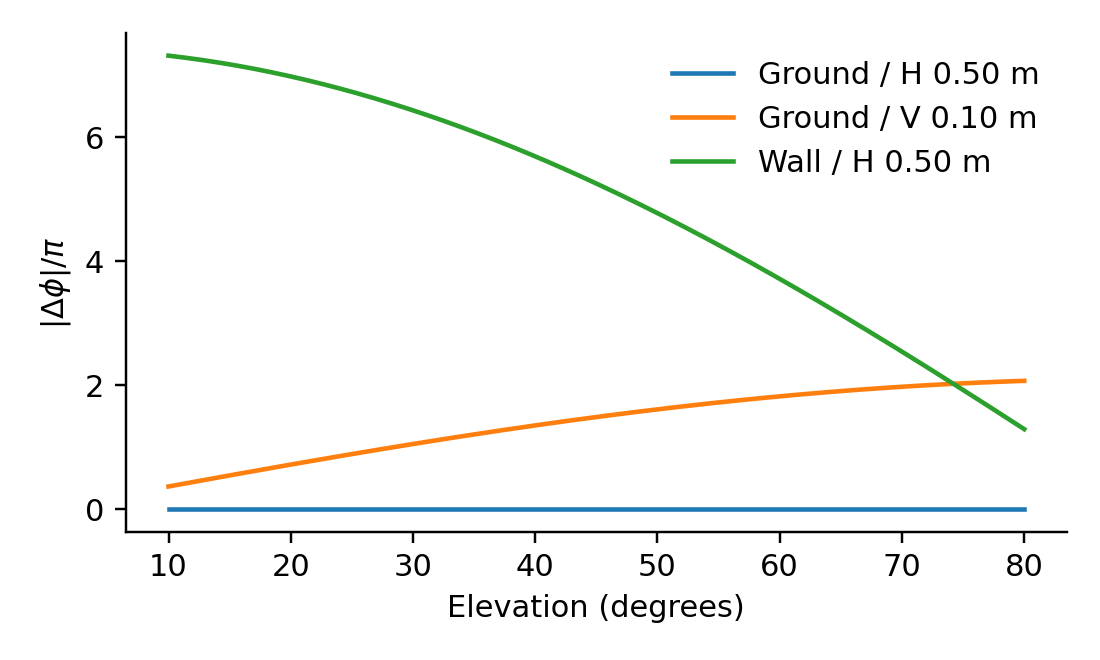

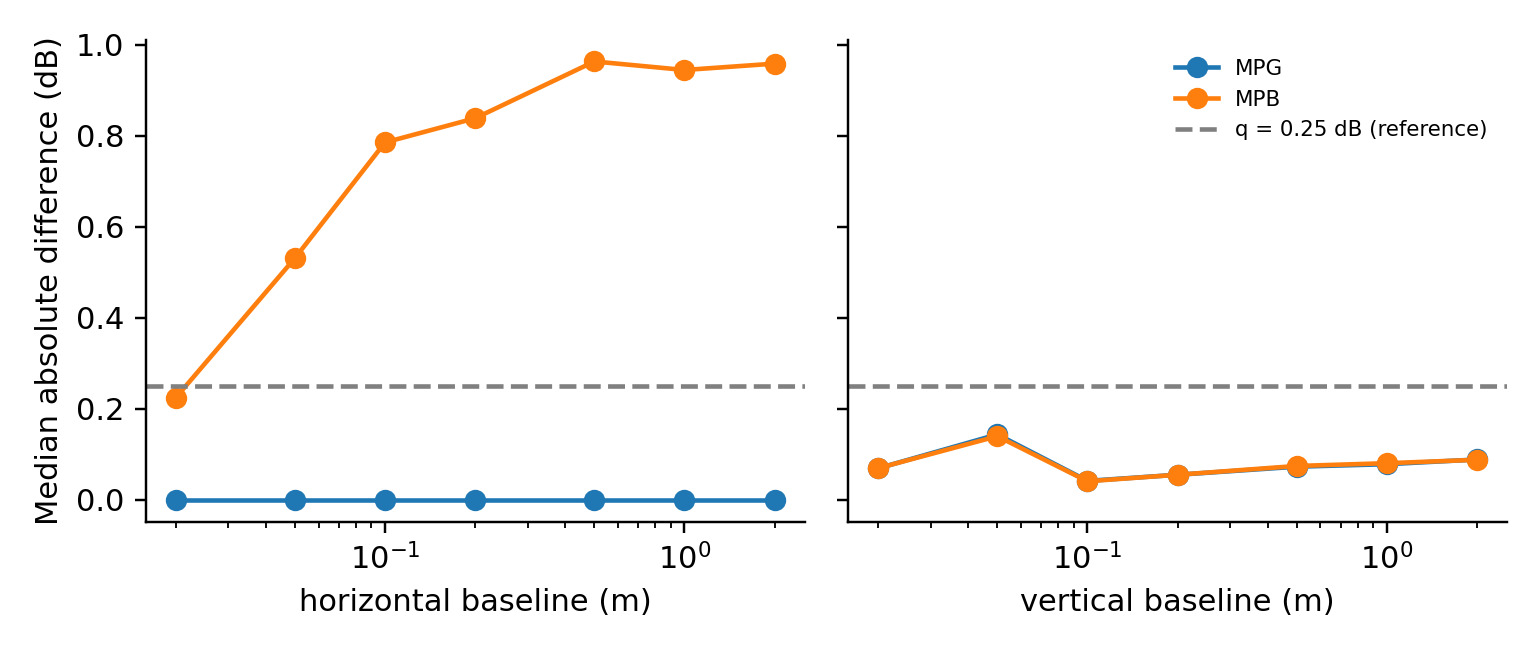

In [5]:
from IPython.display import display, Image, HTML
for name in ["fig_dphi", "fig_delta_vs_baseline"]:
    display(Image(filename=str(OUTPUT_DIR / "figures" / (name + ".png")), width=850))


## 4. E3: paired classification results
The table reports mean balanced accuracy and paired gain over the single channel with the same noise/quantization. ± is the **sample standard deviation across seeds**, not a confidence interval or receiver measurement uncertainty. Full macro-F1, recalls and confusion matrices are in `results.json`.

Configuration,Balanced accuracy (%),Paired gain (pp),Macro-F1
Single,50.31 ± 0.71,0.00 ± 0.00,0.492
H 0.05,53.89 ± 0.45,3.58 ± 0.49,0.527
H 0.50,56.95 ± 0.56,6.63 ± 0.86,0.578
V 0.05,50.31 ± 0.71,-0.00 ± 0.04,0.492
V 0.10,50.36 ± 0.70,0.04 ± 0.04,0.492
Oblique,57.07 ± 0.61,6.76 ± 1.14,0.563
H+V,56.88 ± 0.57,6.57 ± 0.92,0.577
H+H,58.05 ± 0.52,7.73 ± 0.52,0.566
L1-L5,56.86 ± 0.40,6.55 ± 0.84,0.551


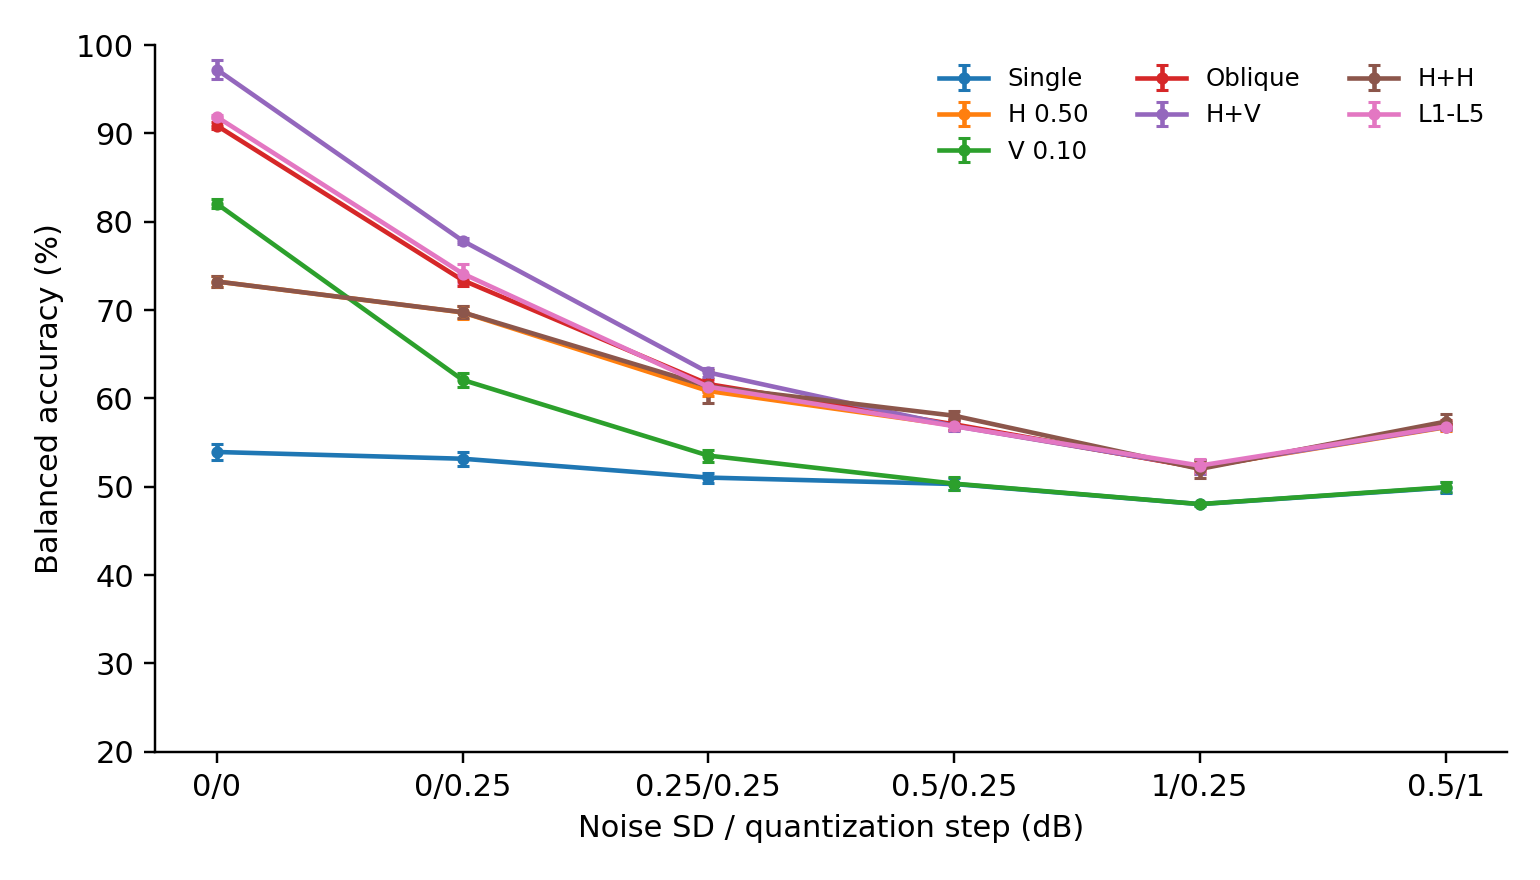

In [6]:
tag = "0.5/0.25"
rows = []
for name, conditions in results["E3"].items():
    v = conditions[tag]
    rows.append(f"<tr><td>{name}</td><td>{100*v['mean']:.2f} ± {100*v['sd']:.2f}</td>"
                f"<td>{v['gain_pp']:.2f} ± {v['gain_sd_pp']:.2f}</td><td>{v['f1']:.3f}</td></tr>")
display(HTML("<table><tr><th>Configuration</th><th>Balanced accuracy (%)</th>"
             "<th>Paired gain (pp)</th><th>Macro-F1</th></tr>" + "".join(rows) + "</table>"))
display(Image(filename=str(OUTPUT_DIR / "figures/fig_bal_acc.png"), width=850))


## 5. E4: exact quantized-observation binary likelihood
Under the specified equal-prior binary hypotheses, the Bayes error is half the overlap of the two discrete difference PMFs. The alternative averages over a uniform phase prior and uses the exact two-ray log-power expression. This calculation assumes independent Gaussian channel error and known amplitude, phase increment and baseline level. It is **not** a bound on the four-class classifier.

At `alpha = 0.05`, the approximate scale ratio is below one but the error remains below chance. Explore different nuisance parameters below without changing the archived results.

D = 0.8597; binary Bayes error = 0.4252; chance error = 0.5
Independent numerical checks: {'phase_quadrature_difference': np.float64(1.6653345369377348e-16), 'monte_carlo_pmf_total_variation': 0.00544527187511249}


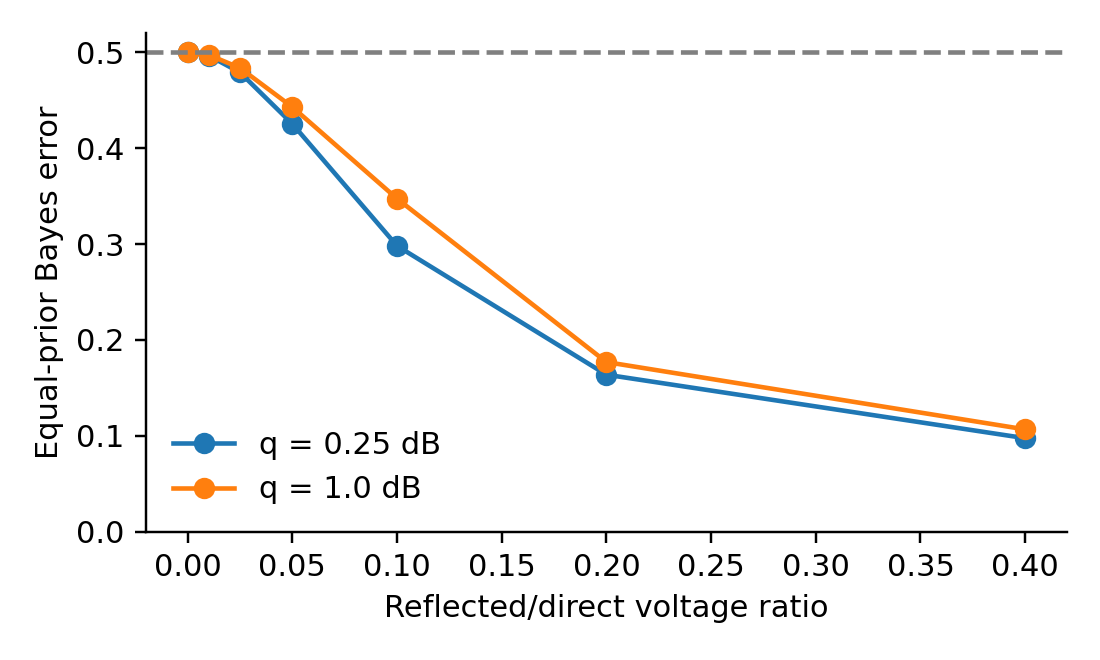

In [7]:
import numpy as np
alpha, sigma, q, phase_step = 0.05, 0.5, 0.25, np.pi
D = sim.rms_delta_db(alpha, phase_step) / np.sqrt(2*sigma**2 + q*q/6)
error = sim.bayes_error(alpha, phase_step, sigma, q)
print(f"D = {D:.4f}; binary Bayes error = {error:.4f}; chance error = 0.5")
print("Independent numerical checks:", results["validation"])
display(Image(filename=str(OUTPUT_DIR / "figures/fig_bayes.png"), width=750))


## 6. E5: calibration, correlation and scene transfer
Each stress column is evaluated separately, not cumulatively. The calibration function matches the injected bias family, so successful recovery does not demonstrate immunity to arbitrary antenna mismatch. The combined scene shift changes multiple parameters; it cannot isolate their individual effects.

In [8]:
tags = ["nominal", "receiver_bias", "calibrated", "correlated_noise", "shifted_scene"]
rows = []
for name, cond in results["E5"].items():
    rows.append("<tr><td>" + name + "</td>" + "".join(f"<td>{100*cond[t]['mean']:.2f}</td>" for t in tags) + "</tr>")
display(HTML("<table><tr><th>Features</th>" + "".join(f"<th>{t}</th>" for t in tags) + "</tr>" + "".join(rows) + "</table>"))


Features,nominal,receiver_bias,calibrated,correlated_noise,shifted_scene
Single,50.28,50.28,50.28,50.31,44.28
H 0.05,54.07,53.62,54.01,54.25,50.31
H 0.50,57.16,54.30,57.07,57.56,53.26
V 0.05,50.27,50.19,50.26,50.33,44.42
V 0.10,50.47,50.41,50.47,50.46,45.16
Oblique,57.43,51.80,57.45,58.58,54.75
H+V,57.15,54.29,57.07,57.56,53.24
H+H,57.28,54.85,57.28,57.20,55.15
L1-L5,57.33,33.09,57.30,57.83,54.20


## 7. Complementary geometry and design scope
The local sensitivity matrix is `G = B.T @ inv(Sigma_difference) @ B`. A shared reference creates covariance between differences even when receiver channel noise is independent. Matrix rank diagnoses geometric first-order nulls; full rank does not prevent phase-wrap nulls at finite wavelength or guarantee classification performance.

H+V local design matrix:
 [[ 0.66666667  0.         -0.06666667]
 [ 0.          0.          0.        ]
 [-0.06666667  0.          0.02666667]]
Eigenvalues: [0.         0.01979598 0.67353735]
Layout ranks: {'horizontal_pair': 1, 'oblique_pair': 1, 'horizontal_vertical': 2, 'three_axes': 3}


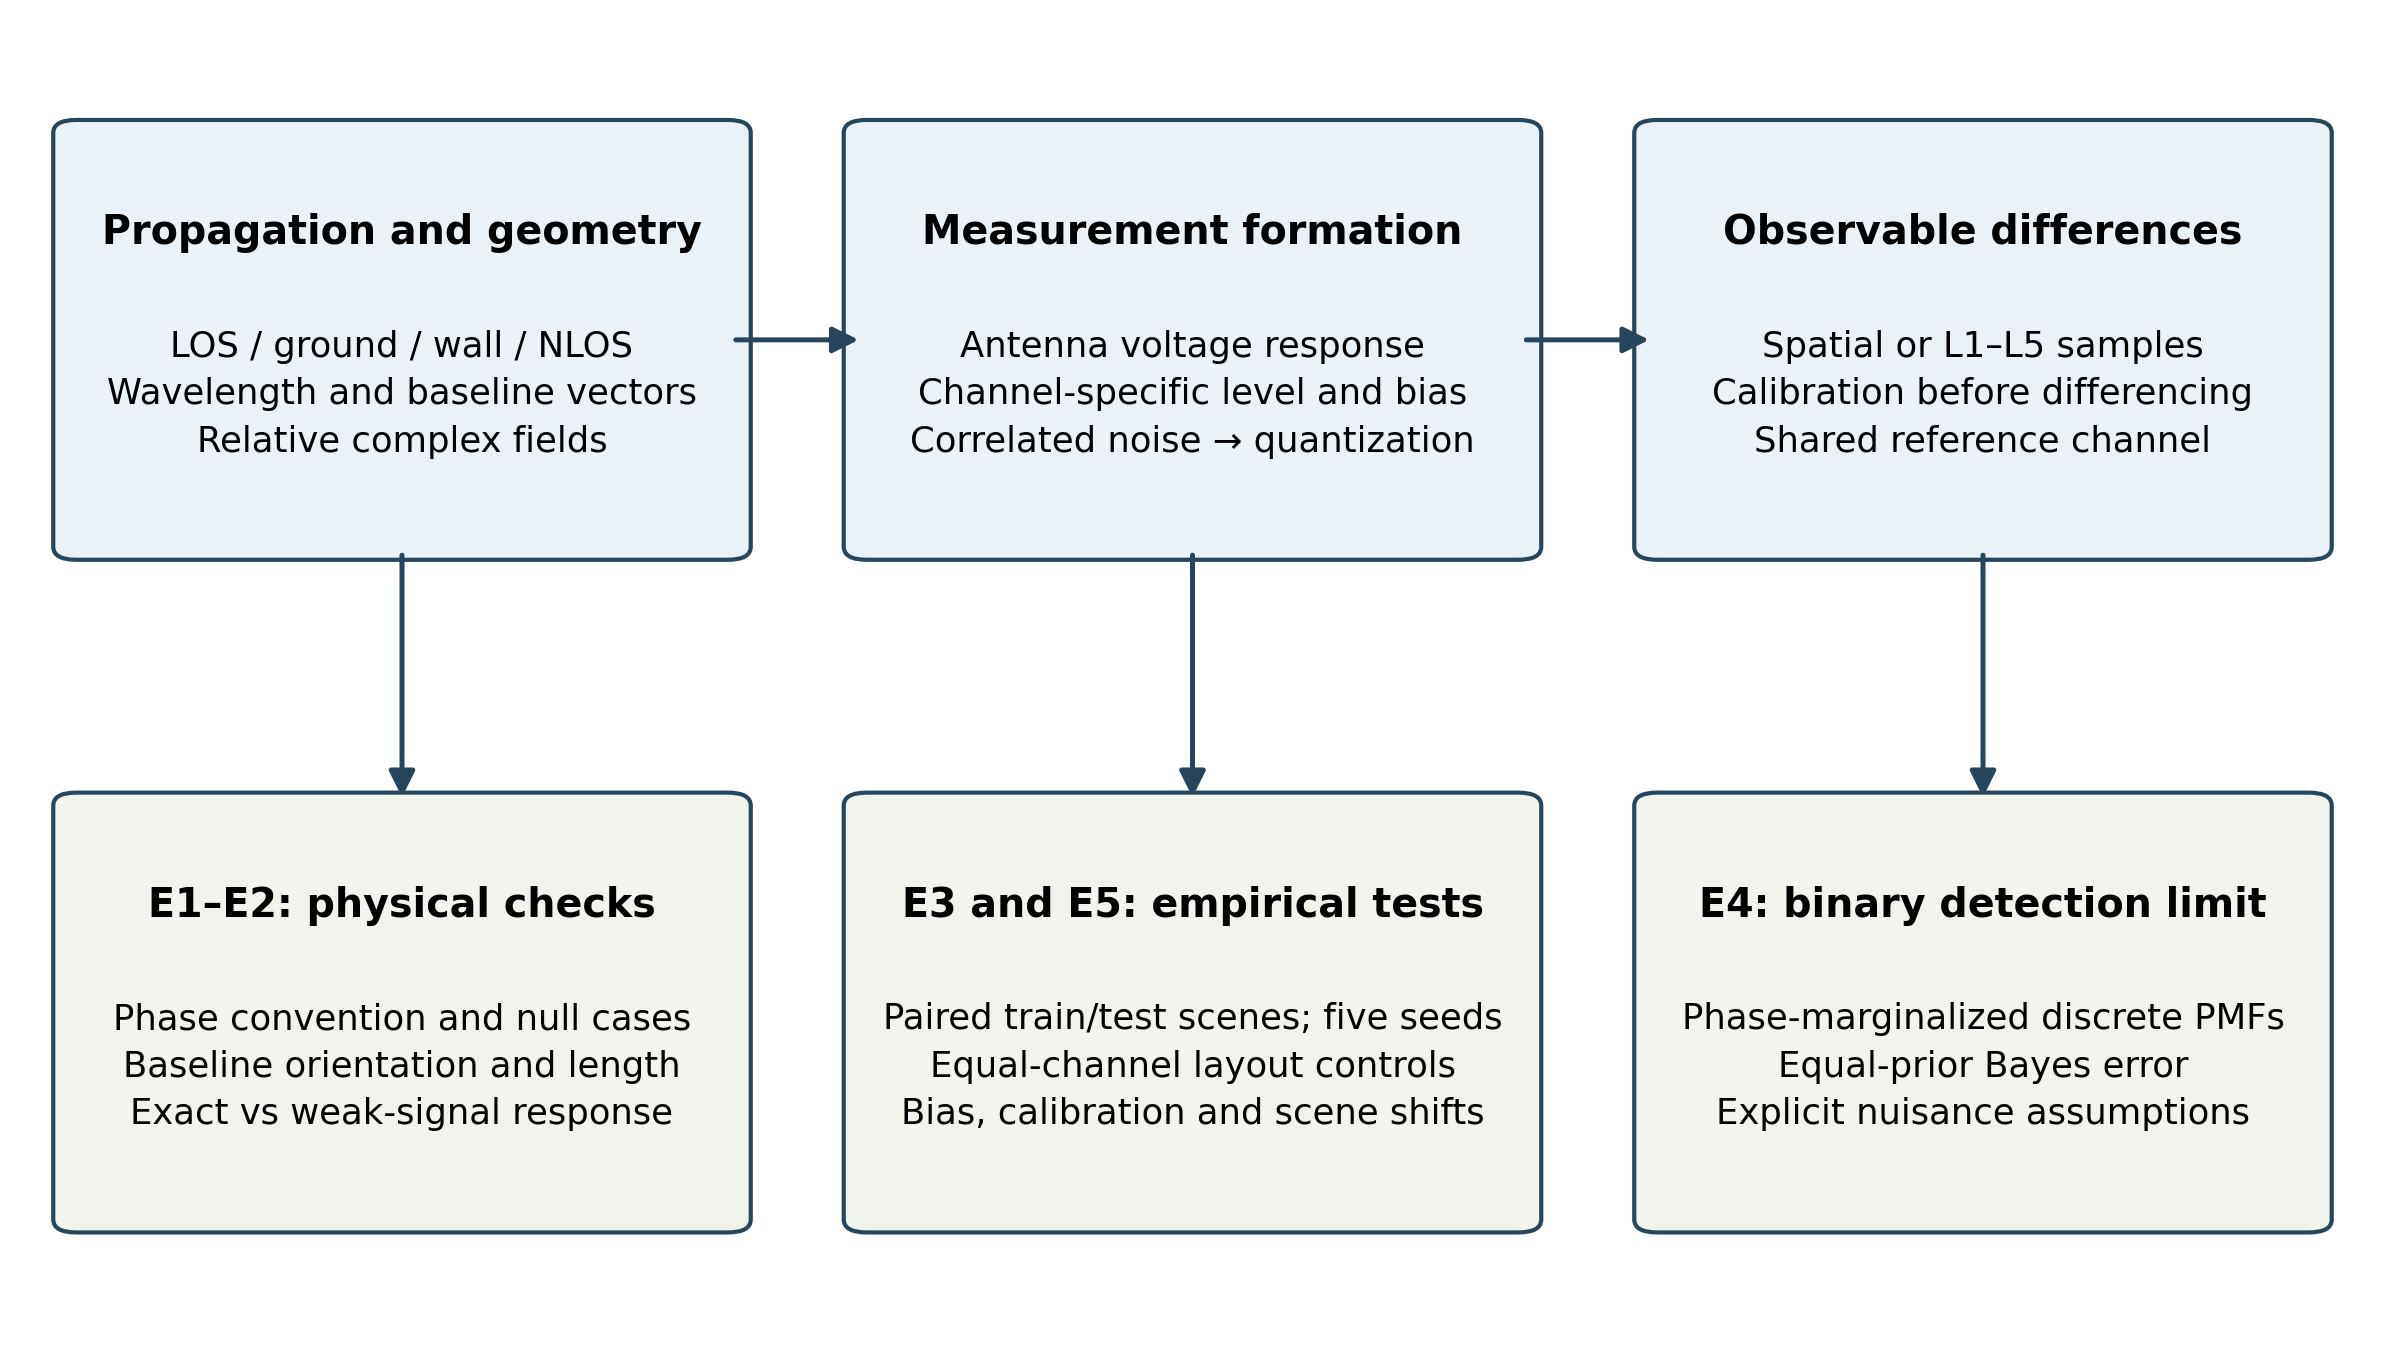

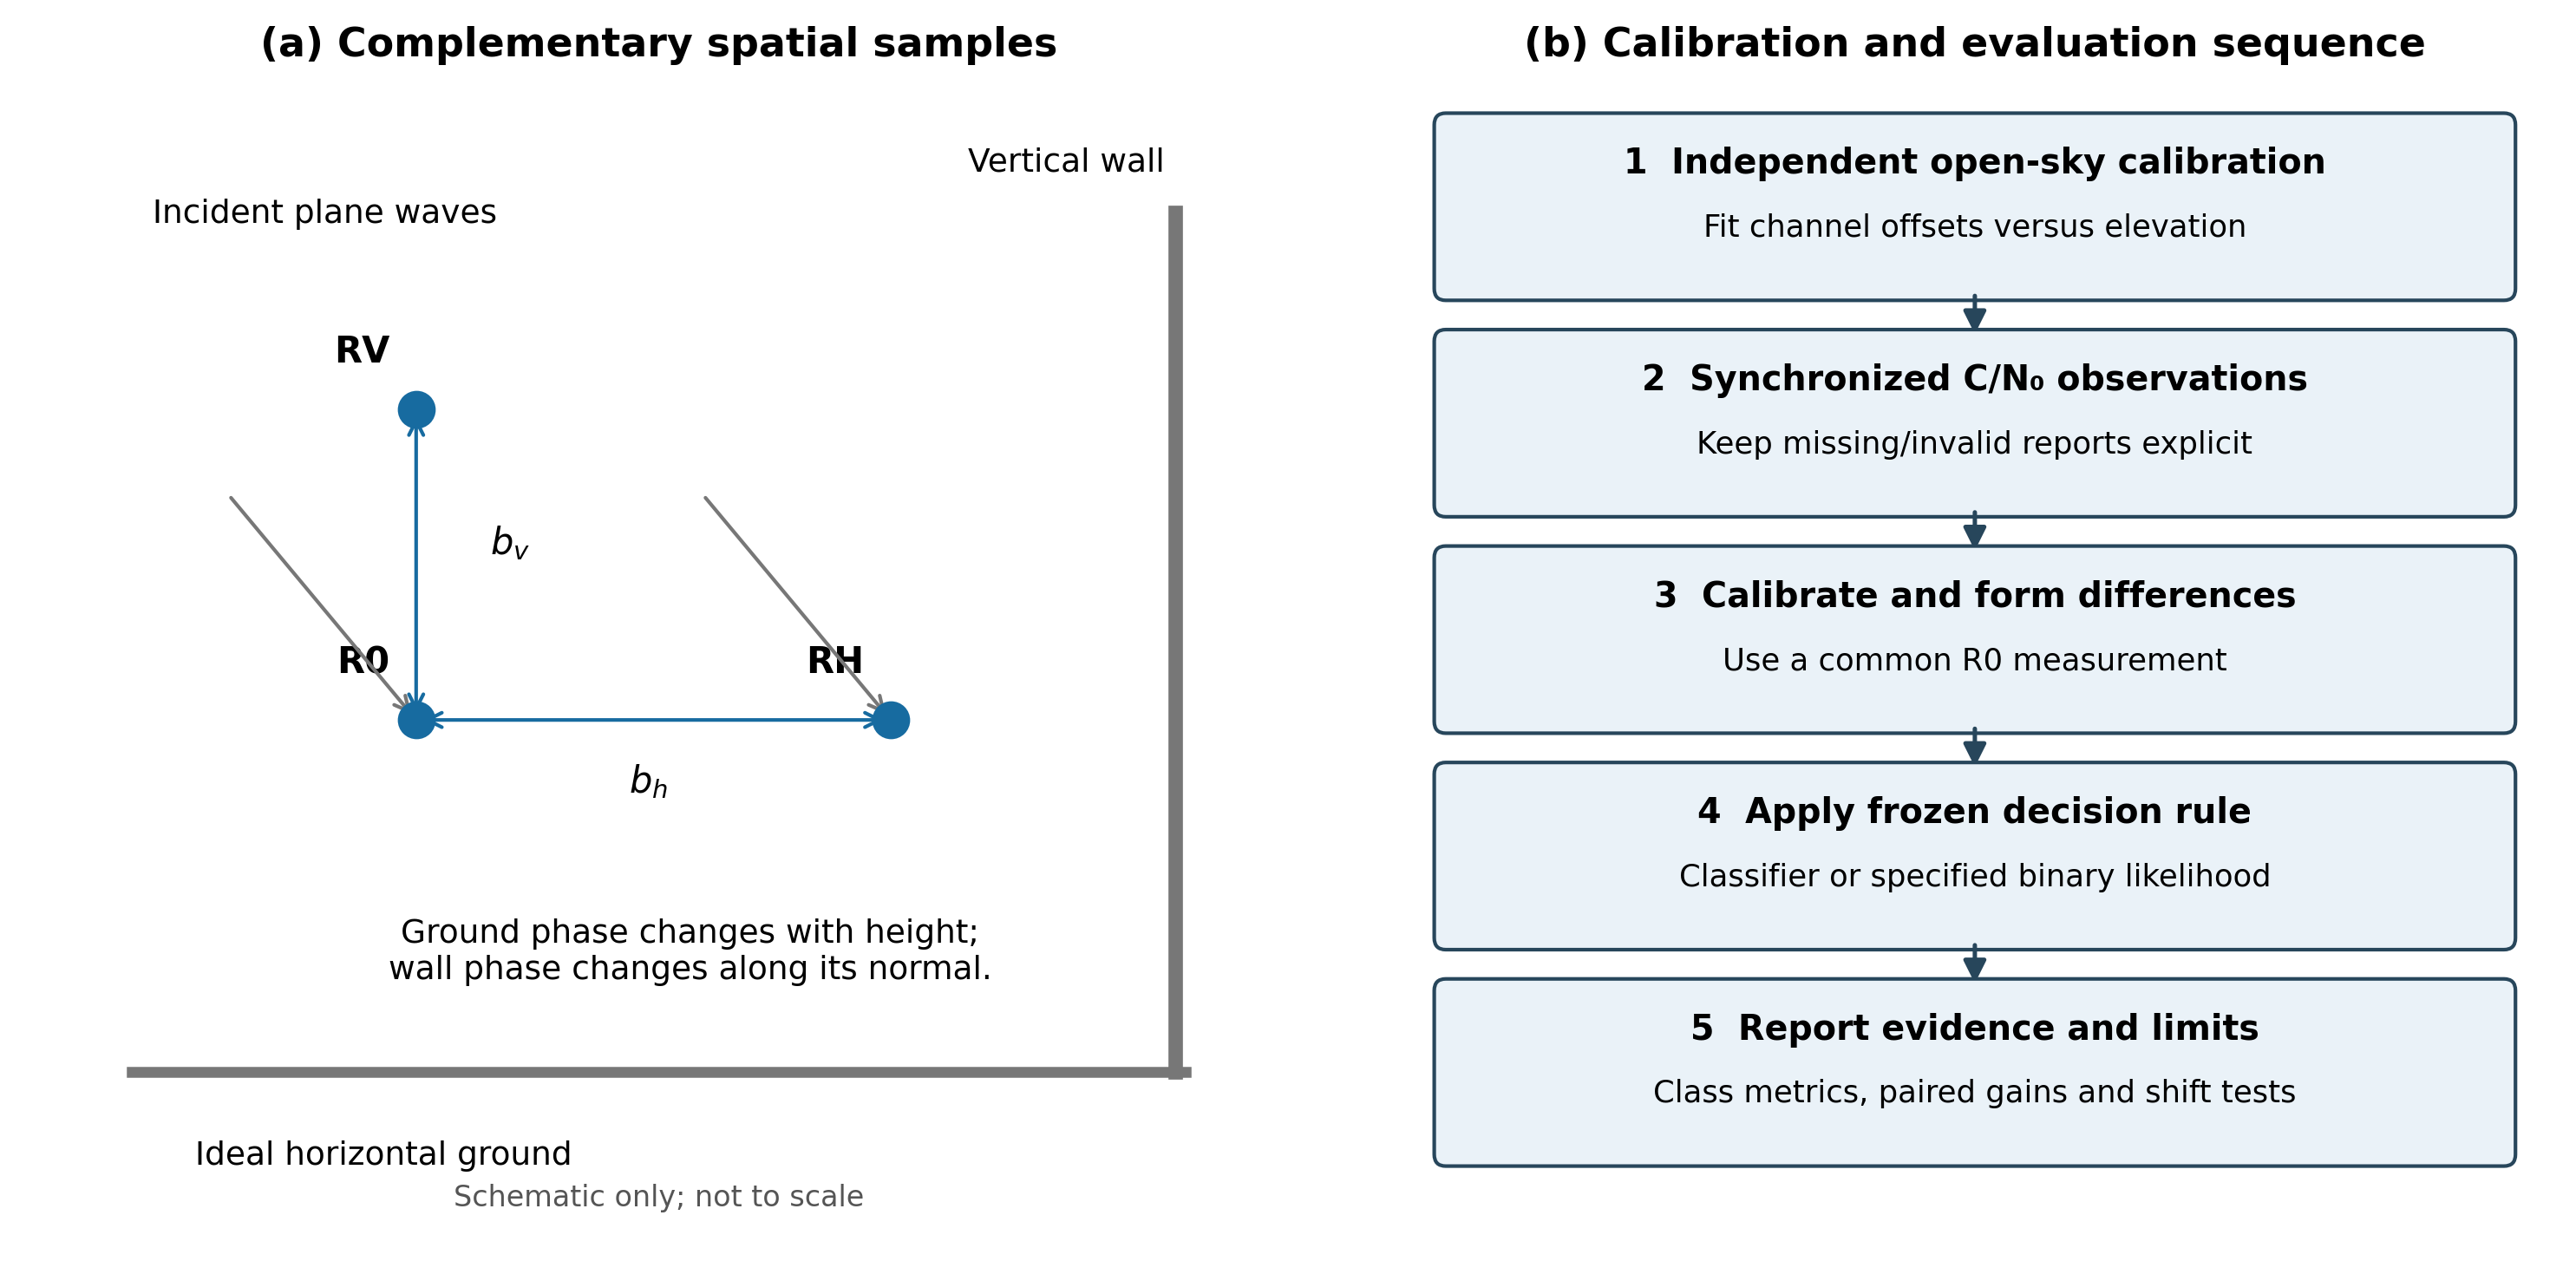

In [9]:
B = np.array([[0.5, 0, 0], [0, 0, 0.1]])
Sigma = 0.5**2 * (np.eye(2) + np.ones((2, 2)))  # No quantization in this local illustration.
G = B.T @ np.linalg.solve(Sigma, B)
print("H+V local design matrix:\n", G)
print("Eigenvalues:", np.linalg.eigvalsh(G))
print("Layout ranks:", results["design_rank"])
for name in ["Framework_overview", "Operation_scheme"]:
    display(Image(filename=str(OUTPUT_DIR / "figures" / (name + ".png")), width=950))


## 8. Export and interpretation checklist
The output directory contains PNG/PDF figures, SVG versions of the overview diagrams, generated LaTeX tables, and `results.json` with seeds, versions and source hashes.

Before any field use: collect measured synchronized channel data; establish quantization, bias, covariance and tracking availability; characterize antenna response; test independent sites and receivers; and assess downstream positioning separately. Do not interpret strong synthetic classification as measured field performance.

In [10]:
assert all(len(r["confusion"]) == 4 for r in results["E3_raw"])
assert len(results["E3_raw"]) == len(SEEDS) * len(experiments.ERRORS) * len(experiments.CONFIGS)
assert results["validation"]["monte_carlo_pmf_total_variation"] < 0.02
print("All expected experiment records and validation checks are present.")


All expected experiment records and validation checks are present.
